<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-kalshi/blob/main/notebooks/01_quoted_depth_depends_on_the_band.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-kalshi/blob/main/notebooks/README.md)

# 01 · Quoted depth depends on the price band

How much of a book is near its best quote? We will read one existing market and one complete order book, translate its two bid ladders into a common YES perspective, and compare quoted contract quantities within a chosen distance from each side's best price.

**Default: recorded public Kalshi responses, not synthetic inputs.** The two complete bodies were acquired sequentially on 2026-11-14 UTC. This is a book snapshot, not a trade tape, probability estimate or execution simulation. No orders, positions or private account data are accessed.

## Select a local price band

`BAND_CENTS` is an integer from **0 to 100 cents per contract**, inclusive. Each side uses its own best quote as the reference. The default **2** includes levels no more than two cents worse than that quote; the experiment changes only **2 → 10**. The complete book is materialized before this local filter, so both runs use identical source data.

`DATA_MODE="live"` explicitly requests a new public snapshot with no fallback. The fixed recorded ticker is the replay default; live may use another existing binary, one-dollar market. Empty books retain diagnostics and omit charts that need price levels. Restart Kernel → Run All after changes.

In [1]:
BAND_CENTS = 2  # Integer cents per contract, 0–100 inclusive; experiment: 10
DATA_MODE = "replay"  # "replay" or "live"; no fallback
MARKET_TICKER = "KXBTCD-26NOV1417-T66999.99"  # One exact market; replay accepts only this ticker

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.1.3":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.1.3"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import prepare

prepare("kalshi")
import kalshi_example as example  # noqa: E402 -- prepare verified companions first

example.initialize(globals())

## Connect to the released worker

This uses Kalshi **v1.3.0**. uv fetches the tagged package and manages its Python runtime.
The release owns the worker dependencies; the SQL stays focused on the connection.
Authentication is explicitly off for these public recorded or live reads.


In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'kalshi' (
 TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-kalshi@v1.3.0 vgi-kalshi',
 auth 'off'
);
CREATE TABLE market_snapshot AS
SELECT ticker,title,subtitle,status,close_time,market_type,notional_value_dollars
FROM kalshi.main.market('{{MARKET_TICKER}}',cache_ttl=>0);
CREATE TABLE book AS
SELECT * FROM kalshi.main.orderbook('{{MARKET_TICKER}}',depth=>0,cache_ttl=>0);

,Count


In [5]:
AS_OF = example.describe_snapshot()

,ticker,title,subtitle,status,close_time,market_type,notional_value_dollars
0,KXBTCD-26NOV1417-T66999.99,"Bitcoin price on Nov 14, 2026?","$67,000 or above",active,2026-11-14 17:00:00-05:00,binary,1.0


**REPLAY · 94 price levels** materialized for this verified one-dollar binary market. Acquisition ended `2026-11-14T07:43:55.243246+00:00`; it is the retrieval clock, not an exchange event timestamp. All subsequent queries use local tables.

## Diagnose availability before calculating a spread

The API returns **YES bids and NO bids**, as described in [Kalshi's orderbook documentation](https://docs.kalshi.com/getting_started/orderbook_responses). Both are bid ladders. For a one-dollar binary contract, a NO bid at `p` corresponds to a YES ask at `1 − p`. This transformation preserves the quoted quantity; it does not create extra liquidity.

The highest YES bid and the lowest implied YES ask define the quoted spread. An absent side has no best quote, so a two-sided spread is unavailable rather than zero. Contract counts are quantities, not numbers of orders or traders. Zero-size levels are diagnosed and excluded from depth; missing or invalid values fail the required-source checks.

In [6]:
%%sql coverage <<
SELECT s.side,count(b.side) AS levels,
 count(*) FILTER (WHERE b.side IS NOT NULL AND b.count_fp=0) AS zero_size_levels,
 count(*) FILTER (WHERE b.side IS NOT NULL AND
  (b.price_dollars IS NULL OR b.count_fp IS NULL OR b.price_dollars<0 OR b.price_dollars>1 OR b.count_fp<0)) AS invalid_levels
FROM (VALUES ('yes'),('no')) s(side) LEFT JOIN book b USING(side)
GROUP BY s.side ORDER BY s.side;

In [7]:
example.check_coverage(coverage)

,side,levels,zero_size_levels,invalid_levels
0,no,48,0,0
1,yes,46,0,0


In [8]:
%%sql
CREATE TABLE yes_ladder AS
SELECT CASE side WHEN 'yes' THEN 'YES bid' ELSE 'YES ask (from NO bid)' END AS book_side,
 CASE side WHEN 'yes' THEN price_dollars ELSE CAST(1 AS DECIMAL(18,4))-price_dollars END AS yes_price,
 count_fp AS contracts
FROM book WHERE count_fp>0;
CREATE TABLE best_quotes AS
SELECT max(yes_price) FILTER (WHERE book_side='YES bid') AS best_bid,
 min(yes_price) FILTER (WHERE book_side='YES ask (from NO bid)') AS best_ask
FROM yes_ladder;

,Count


In [9]:
%%sql quotes <<
SELECT best_bid,best_ask,(best_ask-best_bid)*100 AS spread_cents FROM best_quotes;

In [10]:
example.describe_quotes(quotes)

,best_bid,best_ask,spread_cents
0,0.51,0.52,1.0


The book implies a **YES bid of 51.00 cents**, **YES ask of 52.00 cents**, and **1.00-cent spread**. A negative observed spread would be reported as a snapshot inconsistency, not an arbitrage or execution claim. The separate market-summary quotes are not used to construct this book spread.

## Measure distance from each side's own best price

For bids, worse prices are lower: distance is `best_bid − price`. For implied asks, worse prices are higher: distance is `price − best_ask`. Both distances are in cents per YES contract. The cumulative sum includes all positive quoted quantities from distance zero through the level shown.

The chart uses a linear quantity scale over the complete returned book. Its vertical line selects the local band. Large quantities far from the best price do not imply that comparable quantity exists near the quote.

In [11]:
%%sql
CREATE TABLE distances AS
SELECT l.*,100*CASE WHEN book_side='YES bid' THEN b.best_bid-yes_price
 ELSE yes_price-b.best_ask END AS distance_cents
FROM yes_ladder l CROSS JOIN best_quotes b;
CREATE TABLE cumulative_depth AS
SELECT *,sum(contracts) OVER (PARTITION BY book_side ORDER BY distance_cents
 ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS cumulative_contracts
FROM distances;
CREATE TABLE band_depth AS
SELECT s.book_side,count(d.book_side) AS all_positive_levels,
 coalesce(sum(d.contracts) FILTER (WHERE distance_cents=0),0) AS best_quote_contracts,
 coalesce(sum(d.contracts) FILTER (WHERE distance_cents<={{BAND_CENTS}}),0) AS band_contracts,
 coalesce(sum(d.contracts),0) AS full_book_contracts,
 count(*) FILTER (WHERE distance_cents<={{BAND_CENTS}}) AS band_levels
FROM (VALUES ('YES bid'),('YES ask (from NO bid)')) s(book_side)
LEFT JOIN distances d USING(book_side) GROUP BY s.book_side;

,Count


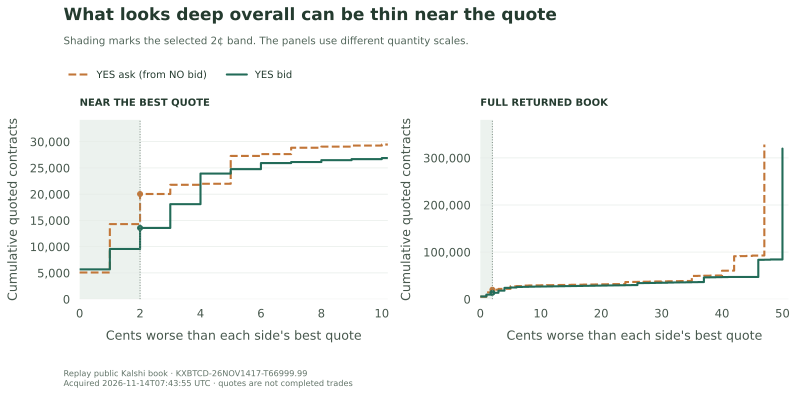

In [12]:
curve = con.execute("SELECT * FROM cumulative_depth ORDER BY book_side,distance_cents").df()
assert curve.distance_cents.ge(0).all()
assert all(part.cumulative_contracts.is_monotonic_increasing for _, part in curve.groupby("book_side"))

source = f"{DATA_MODE.title()} public Kalshi book · {MARKET_TICKER}\nAcquired {AS_OF[:19]} UTC · quotes are not completed trades"
example.plot_depth(curve, BAND_CENTS, source)

## Separate best-quote quantity from additional quantity in the band

The next table preserves both sides, including an empty side's known zero returned quantity. The full-book share uses the same side's entire positive-size ladder as its denominator; it is unavailable when that denominator is zero. The stacked bars count each quoted contract once: quantity at the best price plus additional quantity at worse prices still inside the selected band.

In [13]:
%%sql depth <<
SELECT *,band_contracts*1.0/nullif(full_book_contracts,0) AS band_share
FROM band_depth ORDER BY book_side;

,book_side,all_positive_levels,best_quote_contracts,band_contracts,full_book_contracts,band_levels,band_share
0,YES ask (from NO bid),48,5079.0,20030.54,328418.41,3,0.060991
1,YES bid,46,5672.0,13566.15,319770.75,3,0.042425


**YES ask (from NO bid):** within **2 cents**, **20,030.54 contracts** across **3 levels**, or **6.10%** of that side's full positive-size book. The best quote alone carries **5,079.00 contracts**. These are resting quotes, not completed trades.

**YES bid:** within **2 cents**, **13,566.15 contracts** across **3 levels**, or **4.24%** of that side's full positive-size book. The best quote alone carries **5,672.00 contracts**. These are resting quotes, not completed trades.

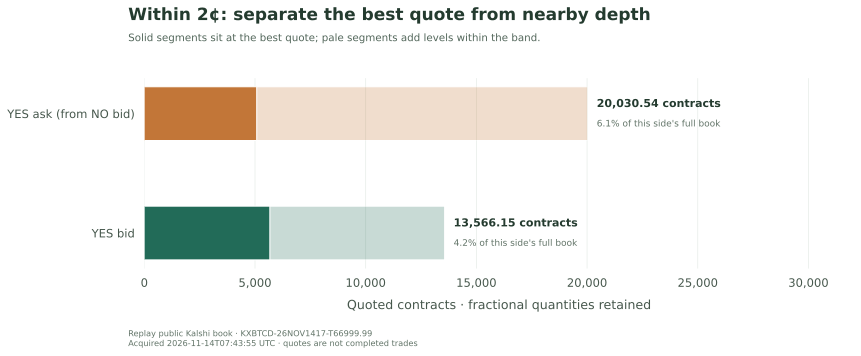

In [14]:
example.describe_band(depth)
example.plot_band(depth, BAND_CENTS, source)

## Experiment: widen only the local band

Change `BAND_CENTS` from **2 to 10** and execute a separate copy. Predict that each side's included quantity and level count can only increase or stay unchanged; their rates of increase can differ. Compare the band quantities, full-book shares and best-versus-additional stacks.

In replay, the source fingerprint, complete depth curves, best quotes, spread and exact two-request audit must stay unchanged. Restore **2** afterwards. A wider band is a different price-distance definition, not newly created liquidity. Fees, cancellations, queue priority, latency and price changes are outside this static analysis; no fill, trading advantage or outcome probability is inferred.

In [15]:
example.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)
